In [1]:
from lights.models import Model
from lights.fits import mass_scan, min_logLL
from lights.plotting import setup_style, sigma_levels
from lights.paths import PLOTS_DIR

import numpy as np
import matplotlib.pyplot as plt

SAVE_DIR = PLOTS_DIR / "mass_fits"
setup_style()

In [2]:
# SM fit: Delta chi^2 of the best-fit SM signal strength relative to mu_SM = 1
mu_min = min_logLL("BelleII").delta_chi2

In [3]:
def plot_mass_scans(mX_vals, scans, xlabel, ylabel, title, xlim, ylim, sigma_labels = 0,
                    label_x = None, label_offset = 1., ncol = 1):
    "Plot Delta chi^2 against the mass for each labelled scan."
    fig, axes = plt.subplots(nrows = 1, ncols = 1)
    sigma_levels(axes, sigma_labels, label_x, label_offset)
    axes.axhline(0, ls = ':', color = 'k')
    axes.axhline(mu_min, ls = ':', color = 'k')     # best-fit SM signal strength
    for label, LL in scans.items():
        axes.plot(mX_vals, LL, label = label)
    axes.set_xlim(*xlim)
    axes.set_ylim(*ylim)
    axes.set_xlabel(xlabel)
    axes.set_ylabel(ylabel)
    axes.legend(loc = 'upper left', fontsize = 14, frameon = False, ncol = ncol)
    plt.title(title, fontsize = 15)
    fig.set_size_inches(6.4, 4.8)
    return fig, axes

# Two-body scenarios

In [4]:
mX_vals = np.append(1e-10, np.linspace(1e-2, 4.0, 1000))

models = {
    r'$C_{\rm SL} + C_{\rm SR},~C_{\rm VL} + C_{\rm VR},~C_{\rm TL} + C_{\rm TR}$': Model("phi", 1., CSL = 1e-8, CSR = 1e-8),
}
LL_2body = {label: mass_scan("BelleII", model, mX_vals) for label, model in models.items()}

Model('phi', mX = 1, CSL = 1e-08, CSR = 1e-08): 100%|██████████| 1001/1001 [00:04<00:00, 204.19it/s]


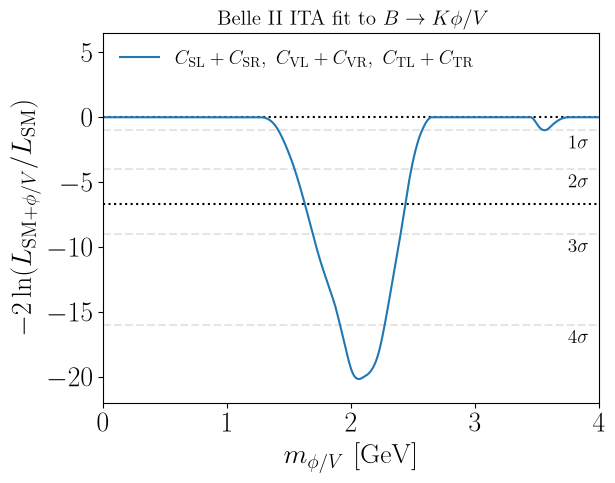

In [5]:
plot_mass_scans(mX_vals, LL_2body, r'$m_{\phi/V} \,\, [\mathrm{GeV}]$',
                r'$-2\ln(L_{\mathrm{SM} + \phi/V}/L_\mathrm{SM})$', r'Belle~II ITA fit to $B\to K \phi/V$',
                xlim = (0, 4), ylim = (-22, 6.5), sigma_labels = 4, label_x = 3.75, label_offset = 1.4)
plt.savefig(SAVE_DIR / "2body_mass.pdf", bbox_inches = 'tight')

# Three-body scenarios

In [6]:
mX_vals = np.append(1e-10, np.linspace(1e-2, 1.5, 1000))

## Scalar pair

In [7]:
models = {
    r'$C_{\rm SL} + C_{\rm SR}$': Model("phiphi", 1., Lambda = 1e4, CSL = 1e-3, CSR = 1e-3),
    r'$C_{\rm VL} + C_{\rm VR}$': Model("phiphi", 1., Lambda = 1e4, CVL = 1., CVR = 1.),
}
LL_scalar = {label: mass_scan("BelleII", model, mX_vals) for label, model in models.items()}

Model('phiphi', mX = 1, Lambda = 10000, CSL = 0.001, CSR = 0.001): 100%|██████████| 1001/1001 [00:02<00:00, 446.32it/s]
Model('phiphi', mX = 1, Lambda = 10000, CVL = 1, CVR = 1): 100%|██████████| 1001/1001 [00:01<00:00, 505.40it/s]


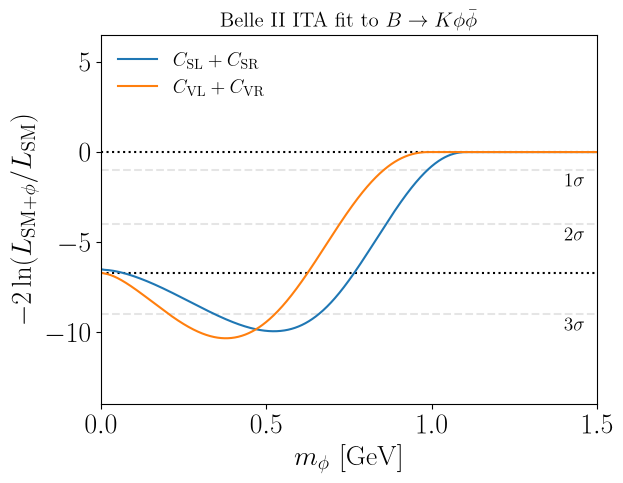

In [8]:
plot_mass_scans(mX_vals, LL_scalar, r'$m_\phi \,\, [\mathrm{GeV}]$',
                r'$-2\ln(L_{\mathrm{SM} + \phi}/L_\mathrm{SM})$', r'Belle~II ITA fit to $B\to K \phi \bar{\phi}$',
                xlim = (0, 1.5), ylim = (-14, 6.5), sigma_labels = 3, label_x = 1.4, label_offset = 0.9)
plt.savefig(SAVE_DIR / "3body_scalar_mass.pdf", bbox_inches = 'tight')

## Fermion pair

In [9]:
models = {
    r'$C_{\rm VL} + C_{\rm VR}$': Model("psipsi", 1., Lambda = 1e4, CVL = 1., CVR = 1.),
    r'$C_{\rm VL}^\prime + C_{\rm VR}^\prime$': Model("psipsi", 1., Lambda = 1e4, CVLp = 1., CVRp = 1.),
    r'$C_{\rm SL} + C_{\rm SR}$': Model("psipsi", 1., Lambda = 1e4, CSL = 1., CSR = 1.),
    r'$C_{\rm SL}^\prime + C_{\rm SR}^\prime$': Model("psipsi", 1., Lambda = 1e4, CSLp = 1., CSRp = 1.),
    r'$C_{\rm TL} + C_{\rm TR}$': Model("psipsi", 1., Lambda = 1e4, CTL = 1., CTR = 1.),
    r'$C_{\rm TL} - C_{\rm TR}$': Model("psipsi", 1., Lambda = 1e4, CTL = 1., CTR = -1.),
}
LL_fermion = {label: mass_scan("BelleII", model, mX_vals) for label, model in models.items()}

Model('psipsi', mX = 1, Lambda = 10000, CVL = 1, CVR = 1): 100%|██████████| 1001/1001 [00:02<00:00, 368.64it/s]
Model('psipsi', mX = 1, Lambda = 10000, CVLp = 1, CVRp = 1): 100%|██████████| 1001/1001 [00:02<00:00, 381.02it/s]
Model('psipsi', mX = 1, Lambda = 10000, CSL = 1, CSR = 1): 100%|██████████| 1001/1001 [00:02<00:00, 356.35it/s]
Model('psipsi', mX = 1, Lambda = 10000, CSLp = 1, CSRp = 1): 100%|██████████| 1001/1001 [00:03<00:00, 310.79it/s]
Model('psipsi', mX = 1, Lambda = 10000, CTL = 1, CTR = 1): 100%|██████████| 1001/1001 [00:02<00:00, 366.24it/s]
Model('psipsi', mX = 1, Lambda = 10000, CTL = 1, CTR = -1): 100%|██████████| 1001/1001 [00:02<00:00, 358.21it/s]


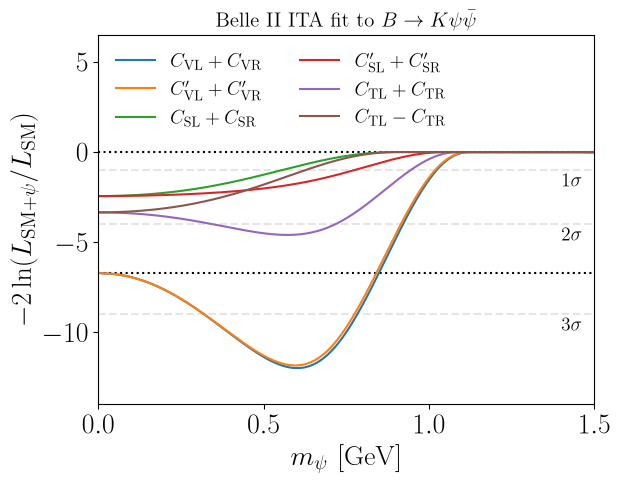

In [10]:
fig, axes = plot_mass_scans(mX_vals, LL_fermion, r'$m_\psi \,\, [\mathrm{GeV}]$',
                            r'$-2\ln(L_{\mathrm{SM} + \psi}/L_\mathrm{SM})$', r'Belle~II ITA fit to $B\to K \psi \bar{\psi}$',
                            xlim = (0, 1.5), ylim = (-14, 6.5), sigma_labels = 3, label_x = 1.4, label_offset = 0.9, ncol = 2)
axes.yaxis.set_label_coords(-0.12, 0.5)
plt.savefig(SAVE_DIR / "3body_fermion_mass.pdf", bbox_inches = 'tight')

## Vector pair

In [11]:
models = {
    r'$C_{\rm SL} + C_{\rm SR}$': Model("VV", 1., Lambda = 3e2, CSL = 1., CSR = 1.),
}
LL_vector = {label: mass_scan("BelleII", model, mX_vals) for label, model in models.items()}

Model('VV', mX = 1, Lambda = 300, CSL = 1, CSR = 1): 100%|██████████| 1001/1001 [00:02<00:00, 408.66it/s]


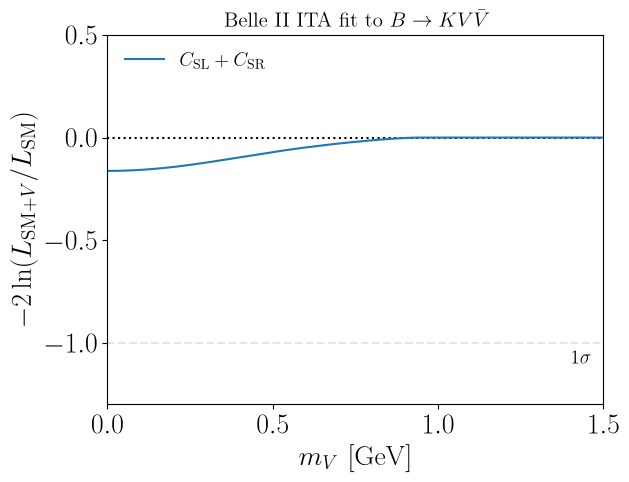

In [12]:
plot_mass_scans(mX_vals, LL_vector, r'$m_V \,\, [\mathrm{GeV}]$',
                r'$-2\ln(L_{\mathrm{SM} + V}/L_\mathrm{SM})$', r'Belle~II ITA fit to $B\to K V \bar{V}$',
                xlim = (0, 1.5), ylim = (-1.3, 0.5), sigma_labels = 1, label_x = 1.4, label_offset = 0.1)
plt.savefig(SAVE_DIR / "3body_vector_mass.pdf", bbox_inches = 'tight')

## Spin-3/2 pair

In [13]:
models = {
    r'$C_{\rm VL} + C_{\rm VR}$': Model("PsiPsi", 1., Lambda = 1e2, CVL = 1., CVR = 1.),
    r'$C_{\rm VL}^\prime + C_{\rm VR}^\prime$': Model("PsiPsi", 1., Lambda = 1e2, CVLp = 1., CVRp = 1.),
    r'$C_{\rm SL} + C_{\rm SR}$': Model("PsiPsi", 1., Lambda = 1e2, CSL = 1., CSR = 1.),
    r'$C_{\rm SL}^\prime + C_{\rm SR}^\prime$': Model("PsiPsi", 1., Lambda = 1e2, CSLp = 1., CSRp = 1.),
    r'$C_{\rm TL} + C_{\rm TR}$': Model("PsiPsi", 1., Lambda = 1e2, CTL = 1., CTR = 1.),
    r'$C_{\rm TL} - C_{\rm TR}$': Model("PsiPsi", 1., Lambda = 1e2, CTL = 1., CTR = -1.),
    r'$C_{\rm TSL} + C_{\rm TSR}$': Model("PsiPsi", 1., Lambda = 1e2, CTSL = 1., CTSR = 1.),
    r'$C_{\rm TSL} - C_{\rm TSR}$': Model("PsiPsi", 1., Lambda = 1e2, CTSL = 1., CTSR = -1.),
    r'$C_{\rm TPL} + C_{\rm TPR}$': Model("PsiPsi", 1., Lambda = 1e2, CTPL = 1., CTPR = 1.),
    r'$C_{\rm TPL} - C_{\rm TPR}$': Model("PsiPsi", 1., Lambda = 1e2, CTPL = 1., CTPR = -1.),
}
LL_spin32 = {label: mass_scan("BelleII", model, mX_vals) for label, model in models.items()}

Model('PsiPsi', mX = 1, Lambda = 100, CVL = 1, CVR = 1): 100%|██████████| 1001/1001 [00:02<00:00, 354.23it/s]
Model('PsiPsi', mX = 1, Lambda = 100, CVLp = 1, CVRp = 1): 100%|██████████| 1001/1001 [00:02<00:00, 382.80it/s]
Model('PsiPsi', mX = 1, Lambda = 100, CSL = 1, CSR = 1): 100%|██████████| 1001/1001 [00:02<00:00, 386.57it/s]
Model('PsiPsi', mX = 1, Lambda = 100, CSLp = 1, CSRp = 1): 100%|██████████| 1001/1001 [00:02<00:00, 382.27it/s]
Model('PsiPsi', mX = 1, Lambda = 100, CTL = 1, CTR = 1): 100%|██████████| 1001/1001 [00:02<00:00, 377.17it/s]
Model('PsiPsi', mX = 1, Lambda = 100, CTL = 1, CTR = -1): 100%|██████████| 1001/1001 [00:02<00:00, 376.75it/s]
Model('PsiPsi', mX = 1, Lambda = 100, CTSL = 1, CTSR = 1): 100%|██████████| 1001/1001 [00:02<00:00, 382.05it/s]
Model('PsiPsi', mX = 1, Lambda = 100, CTSL = 1, CTSR = -1): 100%|██████████| 1001/1001 [00:02<00:00, 381.05it/s]
Model('PsiPsi', mX = 1, Lambda = 100, CTPL = 1, CTPR = 1): 100%|██████████| 1001/1001 [00:02<00:00, 377.25it/s

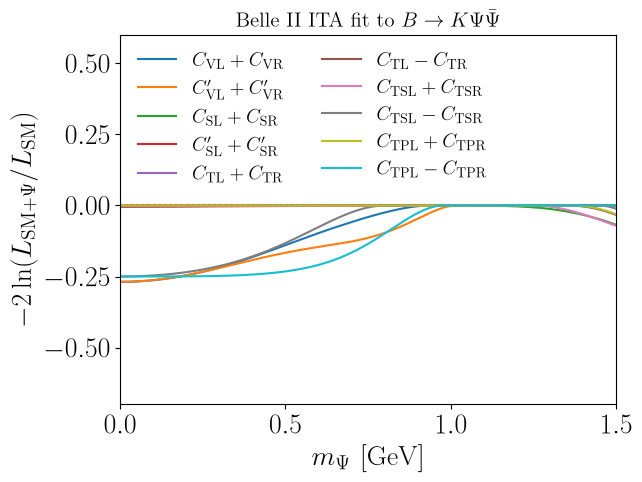

In [14]:
plot_mass_scans(mX_vals, LL_spin32, r'$m_\Psi \,\, [\mathrm{GeV}]$',
                r'$-2\ln(L_{\mathrm{SM} + \Psi}/L_\mathrm{SM})$', r'Belle~II ITA fit to $B\to K \Psi \bar{\Psi}$',
                xlim = (0, 1.5), ylim = (-0.7, 0.6), ncol = 2)
plt.savefig(SAVE_DIR / "3body_spin32_mass.pdf", bbox_inches = 'tight')